# Chapter 1: Why coordinate-free?

Three experiments from the chapter, each in a few lines:

1. An Euler-angle chart reports a violent spin while the body turns calmly.
2. A quaternion PD law takes a body 350° the long way round.
3. Errors built on the manifold stay finite everywhere, and their one bad point is where it should be.

Runs on NumPy, SciPy and Matplotlib only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def hat(x):
    return np.array([[0, -x[2], x[1]], [x[2], 0, -x[0]], [-x[1], x[0], 0.0]])


def vee(M):
    return np.array([M[2, 1], M[0, 2], M[1, 0]])


def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


def Ry(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])


def Rz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

## 1. A calm body, a panicking chart

For yaw-pitch-roll angles $\Theta = (\psi, \theta, \phi)$ the body rate is $\Omega = E(\theta, \phi)\,\dot\Theta$
with $\det E = -\cos\theta$. Hold the body rate fixed and sweep the pitch.

body speed            : 0.707 rad/s
yaw rate at 89 degrees: 40.5 rad/s
det E at 89 degrees   : -0.0175


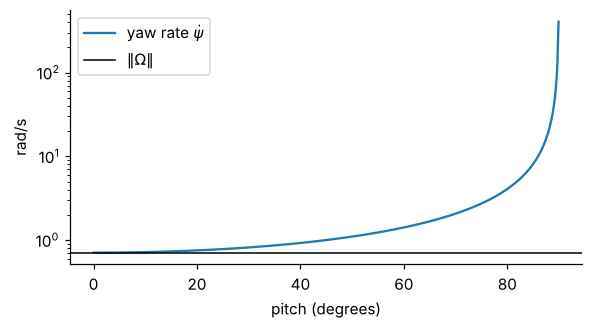

In [2]:
def E(th, phi):
    return np.array([[-np.sin(th), 0, 1],
                     [np.cos(th) * np.sin(phi), np.cos(phi), 0],
                     [np.cos(th) * np.cos(phi), -np.sin(phi), 0]])


Omega = np.array([0.0, 0.5, 0.5])
phi = np.radians(45)
pitch = np.radians(np.linspace(0, 89.9, 400))
rates = np.array([np.linalg.solve(E(th, phi), Omega) for th in pitch])

print(f"body speed            : {np.linalg.norm(Omega):.3f} rad/s")
print(f"yaw rate at 89 degrees: {np.linalg.solve(E(np.radians(89), phi), Omega)[0]:.1f} rad/s")
print(f"det E at 89 degrees   : {np.linalg.det(E(np.radians(89), phi)):.4f}")

plt.figure(figsize=(6, 3))
plt.semilogy(np.degrees(pitch), np.abs(rates[:, 0]), label=r"yaw rate $\dot\psi$")
plt.axhline(np.linalg.norm(Omega), color="k", lw=1, label=r"$\|\Omega\|$")
plt.xlabel("pitch (degrees)")
plt.ylabel("rad/s")
plt.legend()
plt.show()

### The two-labs test

Rotate the world frame by $Y$. The physical error $R_d^\top R$ does not change. The Euler-angle difference does.

In [3]:
def euler_zyx(R):
    return np.array([np.arctan2(R[1, 0], R[0, 0]), -np.arcsin(R[2, 0]), np.arctan2(R[2, 1], R[2, 2])])


R = Rz(0.2) @ Ry(0.3) @ Rx(-0.4)
Rd = Rz(-0.5) @ Ry(0.6) @ Rx(0.1)
Y = Rx(0.9)

print("Euler difference, lab A:", np.round(euler_zyx(R) - euler_zyx(Rd), 3))
print("Euler difference, lab B:", np.round(euler_zyx(Y @ R) - euler_zyx(Y @ Rd), 3))
print("Rd^T R changes by      :", np.abs((Y @ Rd).T @ (Y @ R) - Rd.T @ R).max())

Euler difference, lab A: [ 0.7 -0.3 -0.5]
Euler difference, lab B: [ 0.093 -0.687 -0.782]
Rd^T R changes by      : 1.1102230246251565e-16


## 2. Unwinding

The same physical start, described by $\mathfrak{q}$ or by $-\mathfrak{q}$, under $\tau = -k_p q_v - k_d \Omega$.

same attitude: True


angle turned from  q:   10.0 degrees
angle turned from -q:  350.0 degrees
control effort ratio: 48x


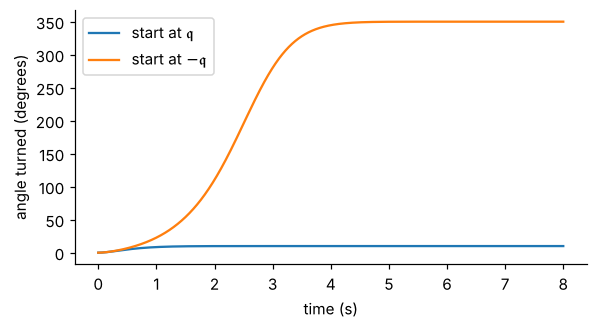

In [4]:
def quat_mul(a, b):
    return np.concatenate([[a[0] * b[0] - a[1:] @ b[1:]],
                           a[0] * b[1:] + b[0] * a[1:] + np.cross(a[1:], b[1:])])


def quat_to_R(q):
    return np.eye(3) + 2 * q[0] * hat(q[1:]) + 2 * hat(q[1:]) @ hat(q[1:])


J = np.diag([0.05, 0.05, 0.10])
kp, kd = 2.0, 0.6


def closed_loop(t, s):
    q, Om = s[:4], s[4:]
    tau = -kp * q[1:] - kd * Om
    return np.concatenate([0.5 * quat_mul(q, np.r_[0.0, Om]),
                           np.linalg.solve(J, tau - np.cross(Om, J @ Om))])


def run(q0, T=8.0):
    t = np.linspace(0, T, 2000)
    sol = solve_ivp(closed_loop, [0, T], np.r_[q0, np.zeros(3)], t_eval=t, rtol=1e-9, atol=1e-11)
    tau = -kp * sol.y[1:4] - kd * sol.y[4:]
    turned = np.degrees(np.concatenate([[0], np.cumsum(np.abs(sol.y[6, 1:]) * np.diff(t))]))
    return t, turned, np.trapezoid(np.sum(tau**2, axis=0), t)


a = np.radians(-10)
q_plus = np.array([np.cos(a / 2), 0, 0, np.sin(a / 2)])
print("same attitude:", np.allclose(quat_to_R(q_plus), quat_to_R(-q_plus)))

t, turned_p, effort_p = run(q_plus)
_, turned_m, effort_m = run(-q_plus)
print(f"angle turned from  q: {turned_p[-1]:6.1f} degrees")
print(f"angle turned from -q: {turned_m[-1]:6.1f} degrees")
print(f"control effort ratio: {effort_m / effort_p:.0f}x")

plt.figure(figsize=(6, 3))
plt.plot(t, turned_p, label=r"start at $\mathfrak{q}$")
plt.plot(t, turned_m, label=r"start at $-\mathfrak{q}$")
plt.xlabel("time (s)")
plt.ylabel("angle turned (degrees)")
plt.legend()
plt.show()

## 3. Error on the manifold

$\Psi_R = \tfrac12 \operatorname{tr}(I - R_d^\top R)$, $e_R = \tfrac12 (R_d^\top R - R^\top R_d)^\vee$.
Sweep the error angle from 0 to 180° about a fixed axis.

at pitch 90 degrees: Psi = 0.9999999999999999  e_R = [0. 1. 0.]
at a half turn     : Psi = 2.0  e_R = [0. 0. 0.]


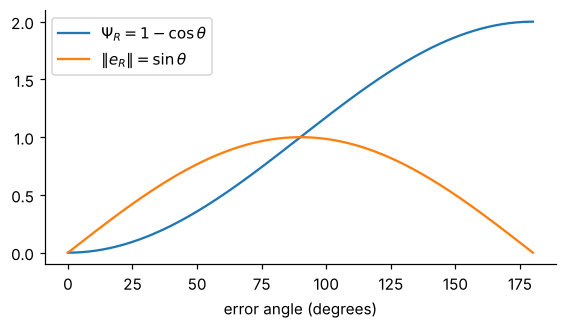

In [5]:
def Psi_R(R, Rd):
    return 0.5 * np.trace(np.eye(3) - Rd.T @ R)


def e_R(R, Rd):
    return 0.5 * vee(Rd.T @ R - R.T @ Rd)


theta = np.linspace(0, np.pi, 200)
psi = [Psi_R(Ry(th), np.eye(3)) for th in theta]
err = [np.linalg.norm(e_R(Ry(th), np.eye(3))) for th in theta]

print("at pitch 90 degrees: Psi =", Psi_R(Ry(np.pi / 2), np.eye(3)), " e_R =", e_R(Ry(np.pi / 2), np.eye(3)))
print("at a half turn     : Psi =", Psi_R(np.diag([1., -1, -1]), np.eye(3)), " e_R =", e_R(np.diag([1., -1, -1]), np.eye(3)))

plt.figure(figsize=(6, 3))
plt.plot(np.degrees(theta), psi, label=r"$\Psi_R = 1 - \cos\theta$")
plt.plot(np.degrees(theta), err, label=r"$\|e_R\| = \sin\theta$")
plt.xlabel("error angle (degrees)")
plt.legend()
plt.show()

The restoring torque is proportional to $\|e_R\|$, which peaks at 90° and fades to zero at 180°. That is the Pitfall at the end of Section 1.5.

### The sphere

Under $\omega = -k\,e_q$ with $e_q = q_d \times q$, the angle to the target obeys $\dot\theta = -k \sin\theta$.
Start very close to the antipode and watch it leave slowly, then arrive.

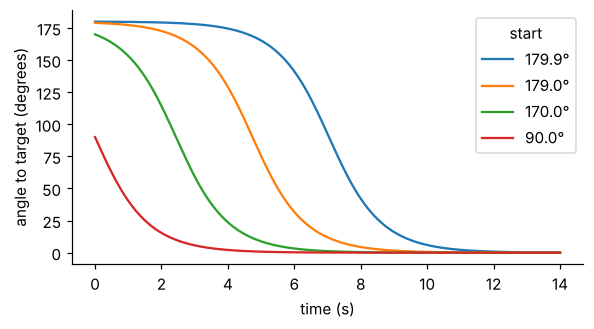

In [6]:
k = 1.0
qd = np.array([0.0, 0.0, 1.0])
plt.figure(figsize=(6, 3))
for start in [179.9, 179.0, 170.0, 90.0]:
    th0 = np.radians(start)
    q0 = np.array([np.sin(th0), 0.0, np.cos(th0)])
    sol = solve_ivp(lambda t, q: np.cross(-k * np.cross(qd, q), q), [0, 14], q0,
                    t_eval=np.linspace(0, 14, 500), rtol=1e-9, atol=1e-11)
    plt.plot(sol.t, np.degrees(np.arccos(np.clip(sol.y.T @ qd, -1, 1))), label=f"{start}°")
plt.xlabel("time (s)")
plt.ylabel("angle to target (degrees)")
plt.legend(title="start")
plt.show()

## Starting points for the exercises

- **Exercise 1.3.** Change `kd` above and recompute the effort ratio. Then replace `-kp * q[1:]` by
  `-kp * np.sign(q[0]) * q[1:]`, add noise to `q`, and start at 179°.
- **Exercise 1.6.** Integrate $\dot\theta = -k\sin\theta$ in closed form and compare with the last plot.